# BigQuery DataFrames in a BigQuery Studio notebook

BigQuery Studio notebooks are Colab Enterprise notebooks that you open from the BigQuery page. They sit in the Explorer next to your datasets and queries, which helps when most of your work is on warehouse tables.

**To run it:** in BigQuery Studio, find **Notebooks** in the Explorer pane and upload this file, then click **Connect**. Like Colab Enterprise, it already runs as you in your project.

This example uses BigQuery DataFrames (`bigframes`). The code looks like pandas, but each step runs as a BigQuery query, so a table with millions of rows never has to fit in the notebook's memory.

`read_gbq` points at a table. It doesn't download anything yet. The table has every US baby name given to at least five babies in a state and year, from 1910 to 2021.

In [1]:
import bigframes.pandas as bpd

bpd.options.bigquery.location = "US"
names = bpd.read_gbq("bigquery-public-data.usa_names.usa_1910_current")
names.shape

(6311504, 5)

`peek()` shows a few rows.

In [2]:
names.peek(5)

,state,gender,year,name,number
149,KY,F,2016,Penny,8
397,ID,F,1993,Kaitlynn,5
420,TN,M,2021,Ryder,94
479,PA,M,1975,Rusty,10
581,IL,F,2019,Gracyn,5


Filter, group, and sort the way you would in pandas. BigQuery does the work and only the 10-row result comes back.

In [3]:
recent = names[names["year"] >= 2000]
top_names = recent.groupby("name")["number"].sum().sort_values(ascending=False).head(10)
top_names

name
Jacob      454809
Michael    414711
Emma       407365
William    378922
Olivia     375834
Ethan      369217
Noah       365225
Matthew    362160
Daniel     356354
Emily      354815
Name: number, dtype: Int64

`to_pandas()` turns the result into a regular pandas object, which you can chart.

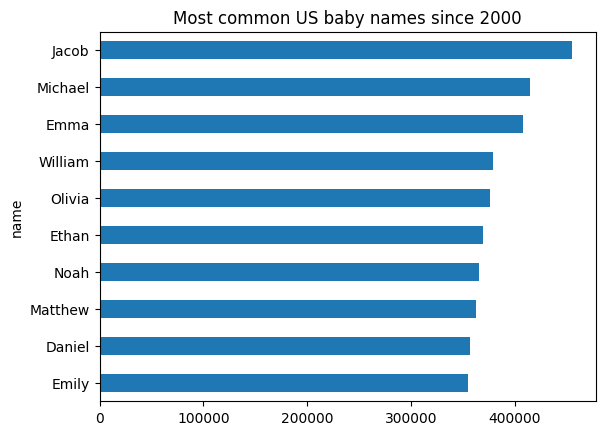

In [4]:
top_names.to_pandas().plot(kind='barh', title='Most common US baby names since 2000').invert_yaxis()